In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from pathlib import Path

PROJECT_DIR = Path(
    r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand"
)

DATA_PATH = PROJECT_DIR / "data" / "processed" / "daily_booking_demand.csv"

print("File exists:", DATA_PATH.exists())
print("Expected location:", DATA_PATH)

File exists: False
Expected location: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\daily_booking_demand.csv


In [1]:
import pandas as pd
from pathlib import Path

EXCEL_PATH = Path(
    r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\raw\BK_AUG2026.xlsx"
)

print("Excel file exists:", EXCEL_PATH.exists())

Excel file exists: True


In [2]:
df = pd.read_excel(EXCEL_PATH)

print("Data loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Data loaded successfully!
Shape: (635483, 34)
Columns: ['LRNO', 'NOA', 'BKDATE', 'NOA.1', 'AWGT', 'CHWGT', 'BKMODE', 'SEGMENT', 'DECLVALUE', 'CONSIGNOR', 'CONSIGNEE', 'SENDTIN', 'RECTIN', 'COMODITY', 'DESCRIPTION', 'PACKING', 'GCTOTAL', 'FRGT', 'ST', 'HAMALI', 'VSC', 'CRC', 'DDL', 'OTHERS', 'CART', 'WITHPASS', 'DOORCOLL', 'BKGODA', 'TOLLCHR', 'REMARK', 'ACPARTYCODE', 'INVNO', 'EWAYBILLNO', 'LOADTYPE']


In [3]:
# Convert booking date
df["BKDATE"] = pd.to_datetime(
    df["BKDATE"],
    errors="coerce",
    dayfirst=True
)

# Remove rows without valid booking dates
df = df.dropna(subset=["BKDATE"])

# Count bookings per day
daily_bookings = (
    df.groupby(df["BKDATE"].dt.normalize())
      .size()
      .reset_index(name="BOOKING_COUNT")
)

daily_bookings = daily_bookings.rename(
    columns={"BKDATE": "DATE"}
)

daily_bookings = daily_bookings.sort_values("DATE")

daily_bookings.head()

,DATE,BOOKING_COUNT
0,1970-01-01,1
1,2026-08-01,53116
2,2026-08-02,7336
3,2026-08-03,46339
4,2026-08-04,49664


In [4]:
PROJECT_DIR = Path(
    r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROCESSED_DIR / "daily_booking_demand.csv"

daily_bookings.to_csv(DATA_PATH, index=False)

print("File saved successfully!")
print(DATA_PATH)

File saved successfully!
F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\daily_booking_demand.csv


In [5]:
df = pd.read_csv(DATA_PATH)

df["DATE"] = pd.to_datetime(df["DATE"])

print("Data loaded successfully!")
print("Shape:", df.shape)

df.head()

Data loaded successfully!
Shape: (16, 2)


,DATE,BOOKING_COUNT
0,1970-01-01,1
1,2026-08-01,53116
2,2026-08-02,7336
3,2026-08-03,46339
4,2026-08-04,49664


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project paths
PROJECT_DIR = r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand"

DATA_PATH = os.path.join(
    PROJECT_DIR, "data", "processed", "daily_booking_demand.csv"
)

# Check file
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Load dataset
df = pd.read_csv(DATA_PATH)

df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
df = df.dropna(subset=["DATE"]).copy()
df = df.sort_values("DATE").reset_index(drop=True)

print("Data loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Data loaded successfully!
Shape: (335, 2)


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-01-09,NaN
2,2026-01-10,NaN
3,2026-01-11,NaN
4,2026-01-12,NaN


In [2]:
print("=" * 50)
print("TIME SERIES DATA OVERVIEW")
print("=" * 50)

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDate range:")
print(df["DATE"].min(), "to", df["DATE"].max())

print("\nDuplicate dates:", df["DATE"].duplicated().sum())

TIME SERIES DATA OVERVIEW

Dataset shape: (335, 2)

Column names:
['DATE', 'BOOKING_COUNT']

Data types:
DATE             datetime64[ns]
BOOKING_COUNT           float64
dtype: object

Missing values:
DATE               0
BOOKING_COUNT    323
dtype: int64

Date range:
2026-01-08 00:00:00 to 2026-12-08 00:00:00

Duplicate dates: 0


In [3]:
print("=" * 50)
print("TIME SERIES DATA OVERVIEW")
print("=" * 50)

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDate range:")
print(df["DATE"].min(), "to", df["DATE"].max())

print("\nDuplicate dates:", df["DATE"].duplicated().sum())

TIME SERIES DATA OVERVIEW

Dataset shape: (335, 2)

Column names:
['DATE', 'BOOKING_COUNT']

Data types:
DATE             datetime64[ns]
BOOKING_COUNT           float64
dtype: object

Missing values:
DATE               0
BOOKING_COUNT    323
dtype: int64

Date range:
2026-01-08 00:00:00 to 2026-12-08 00:00:00

Duplicate dates: 0


In [5]:
# Identify the booking demand column
possible_columns = [
    "BOOKING_COUNT",
    "booking_count",
    "BOOKINGS",
    "bookings",
    "DEMAND",
    "demand",
    "COUNT",
    "count"
]

demand_col = next(
    (col for col in possible_columns if col in df.columns),
    None
)

if demand_col is None:
    raise ValueError(
        "Booking demand column not found. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Booking demand column:", demand_col)

Booking demand column: BOOKING_COUNT


In [6]:
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
df["BOOKING_COUNT"] = pd.to_numeric(
    df["BOOKING_COUNT"], errors="coerce"
)

df = df.dropna(subset=["DATE", "BOOKING_COUNT"])
df = df.sort_values("DATE")

daily_df = (
    df.groupby("DATE")["BOOKING_COUNT"]
    .sum()
    .to_frame()
)

print("Daily time-series data prepared!")
display(daily_df.head())

Daily time-series data prepared!


,BOOKING_COUNT
DATE,
2026-01-08,13691.0
2026-02-08,1913.0
2026-03-08,11381.0
2026-04-08,12809.0
2026-05-08,12559.0


In [7]:
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
df["BOOKING_COUNT"] = pd.to_numeric(
    df["BOOKING_COUNT"], errors="coerce"
)

df = df.dropna(subset=["DATE", "BOOKING_COUNT"])
df = df.sort_values("DATE")

daily_df = (
    df.groupby("DATE")["BOOKING_COUNT"]
    .sum()
    .to_frame()
)

print("Daily time-series data prepared!")
display(daily_df.head())

Daily time-series data prepared!


,BOOKING_COUNT
DATE,
2026-01-08,13691.0
2026-02-08,1913.0
2026-03-08,11381.0
2026-04-08,12809.0
2026-05-08,12559.0


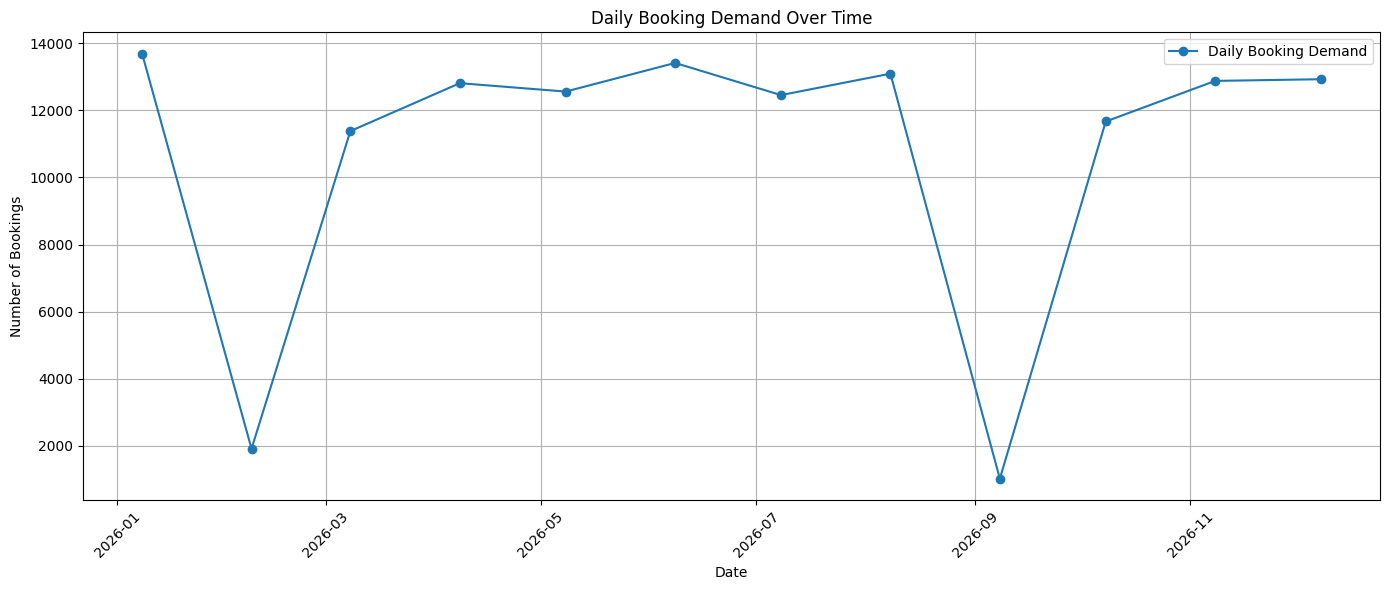

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    daily_df.index,
    daily_df["BOOKING_COUNT"],
    marker="o",
    label="Daily Booking Demand"
)

plt.title("Daily Booking Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
print("BOOKING DEMAND STATISTICS")
print("=" * 40)

print("Total bookings:", daily_df["BOOKING_COUNT"].sum())
print("Average bookings:", daily_df["BOOKING_COUNT"].mean())
print("Maximum bookings:", daily_df["BOOKING_COUNT"].max())
print("Minimum bookings:", daily_df["BOOKING_COUNT"].min())
print("Standard deviation:", daily_df["BOOKING_COUNT"].std())

BOOKING DEMAND STATISTICS
Total bookings: 129803.0
Average bookings: 10816.916666666666
Maximum bookings: 13691.0
Minimum bookings: 1020.0
Standard deviation: 4419.535093985532


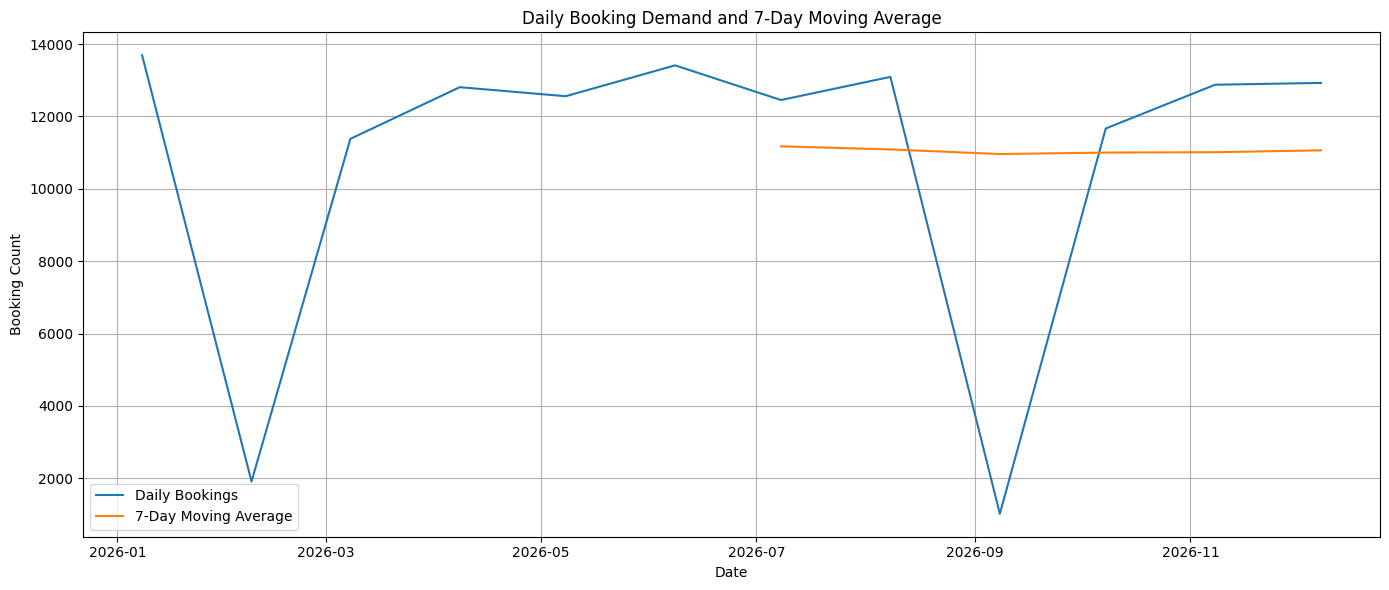

In [10]:
daily_df["7_DAY_MA"] = (
    daily_df["BOOKING_COUNT"].rolling(window=7).mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_df.index,
    daily_df["BOOKING_COUNT"],
    label="Daily Bookings"
)

plt.plot(
    daily_df.index,
    daily_df["7_DAY_MA"],
    label="7-Day Moving Average"
)

plt.title("Daily Booking Demand and 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Booking Count")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
# Identify the booking demand column
possible_columns = [
    "BOOKING_COUNT",
    "booking_count",
    "BOOKINGS",
    "bookings",
    "DEMAND",
    "demand",
    "COUNT",
    "count"
]

demand_col = next(
    (col for col in possible_columns if col in df.columns),
    None
)

if demand_col is None:
    raise ValueError(
        "Booking demand column not found. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Booking demand column:", demand_col)

Booking demand column: BOOKING_COUNT


In [16]:
# Prepare the time-series data
forecast_df = daily_df[["BOOKING_COUNT"]].copy()

# Sort data by date
forecast_df = forecast_df.sort_index()

# Split data: 80% training and 20% testing
split_index = int(len(forecast_df) * 0.8)

train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()

print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)

print("\nTraining data:")
display(train.head())

print("\nTesting data:")
display(test.head())

Training data shape: (9, 1)
Testing data shape: (3, 1)

Training data:


,BOOKING_COUNT
DATE,
2026-01-08,13691.0
2026-02-08,1913.0
2026-03-08,11381.0
2026-04-08,12809.0
2026-05-08,12559.0



Testing data:


,BOOKING_COUNT
DATE,
2026-10-08,11667.0
2026-11-08,12877.0
2026-12-08,12927.0


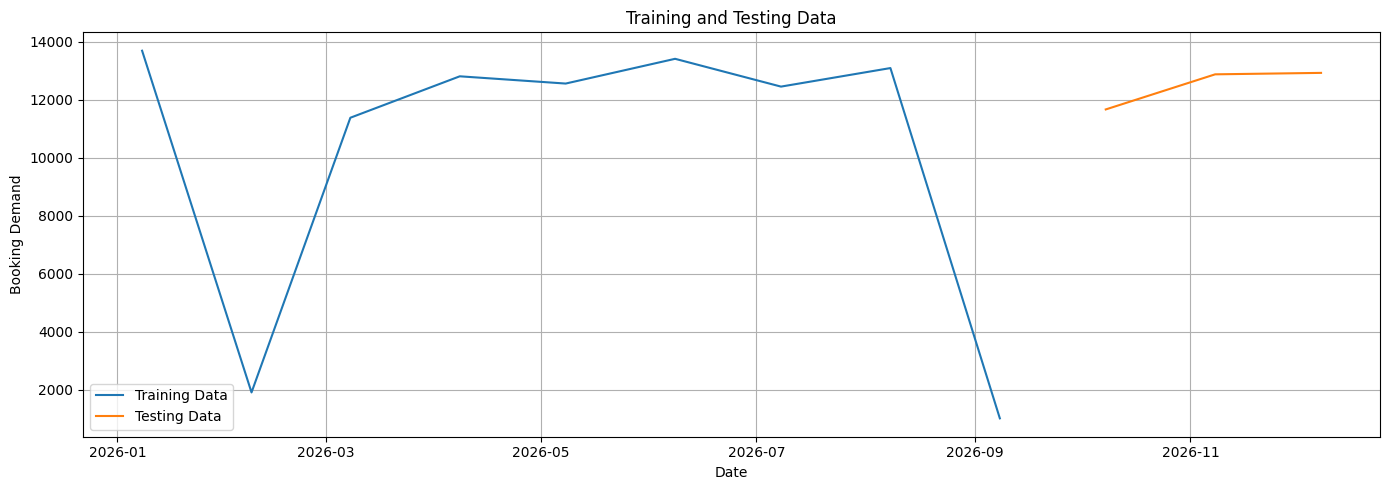

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    train.index,
    train["BOOKING_COUNT"],
    label="Training Data"
)

plt.plot(
    test.index,
    test["BOOKING_COUNT"],
    label="Testing Data"
)

plt.title("Training and Testing Data")
plt.xlabel("Date")
plt.ylabel("Booking Demand")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Monthly booking demand:


DATE
2026-01-01    13691.0
2026-02-01     1913.0
2026-03-01    11381.0
2026-04-01    12809.0
2026-05-01    12559.0
2026-06-01    13412.0
2026-07-01    12454.0
2026-08-01    13093.0
2026-09-01     1020.0
2026-10-01    11667.0
2026-11-01    12877.0
2026-12-01    12927.0
Freq: MS, Name: BOOKING_COUNT, dtype: float64

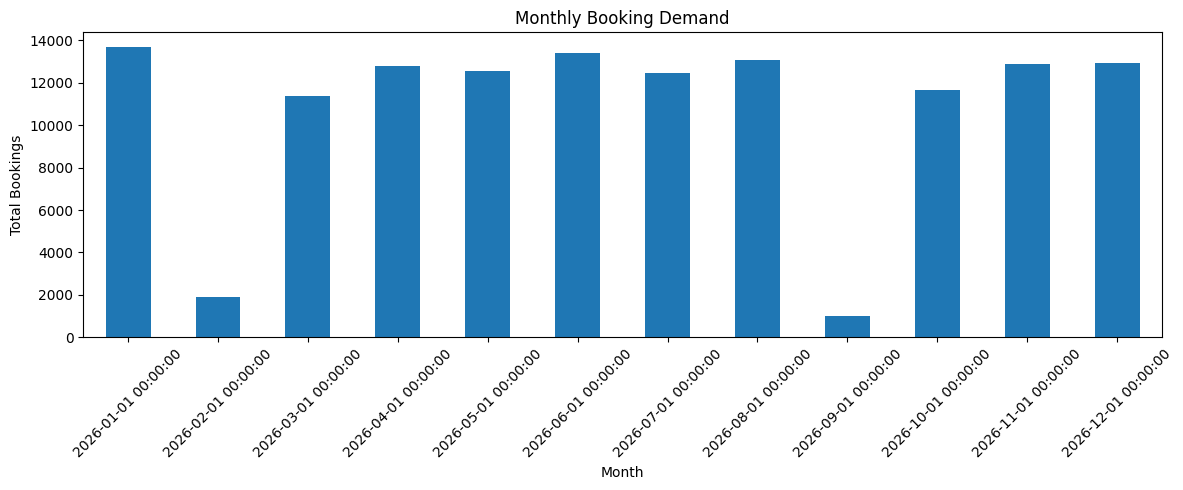

In [18]:
monthly_demand = daily_df[demand_col].resample("MS").sum()

print("Monthly booking demand:")
display(monthly_demand)

plt.figure(figsize=(12, 5))
monthly_demand.plot(kind="bar")

plt.title("Monthly Booking Demand")
plt.xlabel("Month")
plt.ylabel("Total Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
print("TIME SERIES STATISTICS")
print("=" * 50)

print("\nMean demand:", daily_df[demand_col].mean())
print("Median demand:", daily_df[demand_col].median())
print("Minimum demand:", daily_df[demand_col].min())
print("Maximum demand:", daily_df[demand_col].max())
print("Standard deviation:", daily_df[demand_col].std())

display(daily_df[demand_col].describe())

TIME SERIES STATISTICS

Mean demand: 10816.916666666666
Median demand: 12684.0
Minimum demand: 1020.0
Maximum demand: 13691.0
Standard deviation: 4419.535093985532


count       12.000000
mean     10816.916667
std       4419.535094
min       1020.000000
25%      11595.500000
50%      12684.000000
75%      12968.500000
max      13691.000000
Name: BOOKING_COUNT, dtype: float64

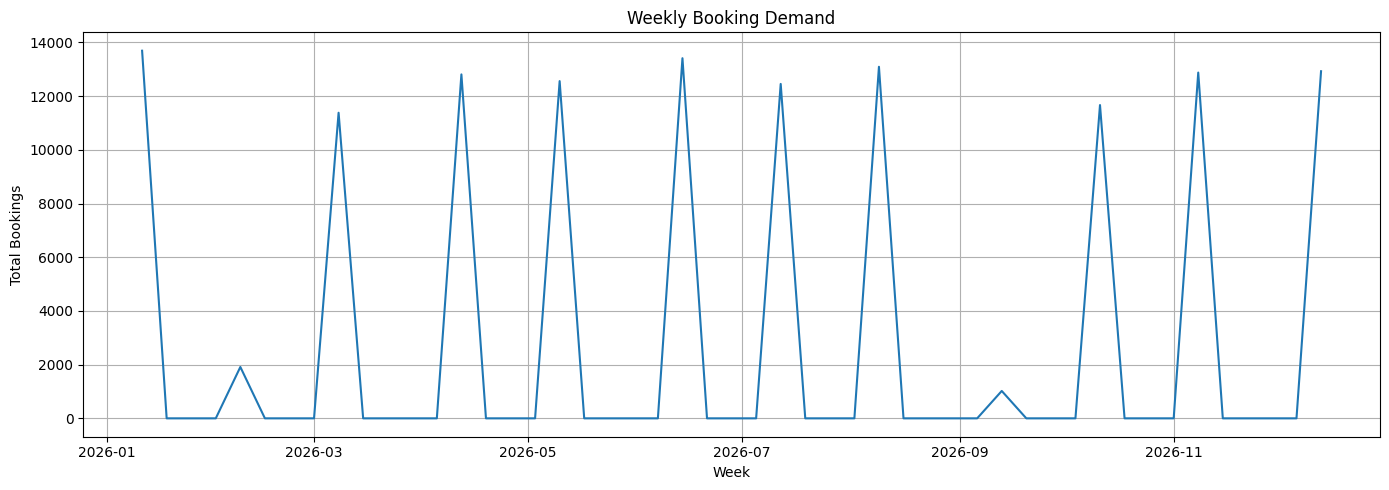

In [21]:
weekly_demand = daily_df[demand_col].resample("W").sum()

plt.figure(figsize=(14, 5))
plt.plot(weekly_demand.index, weekly_demand.values)

plt.title("Weekly Booking Demand")
plt.xlabel("Week")
plt.ylabel("Total Bookings")
plt.grid(True)
plt.tight_layout()
plt.show()

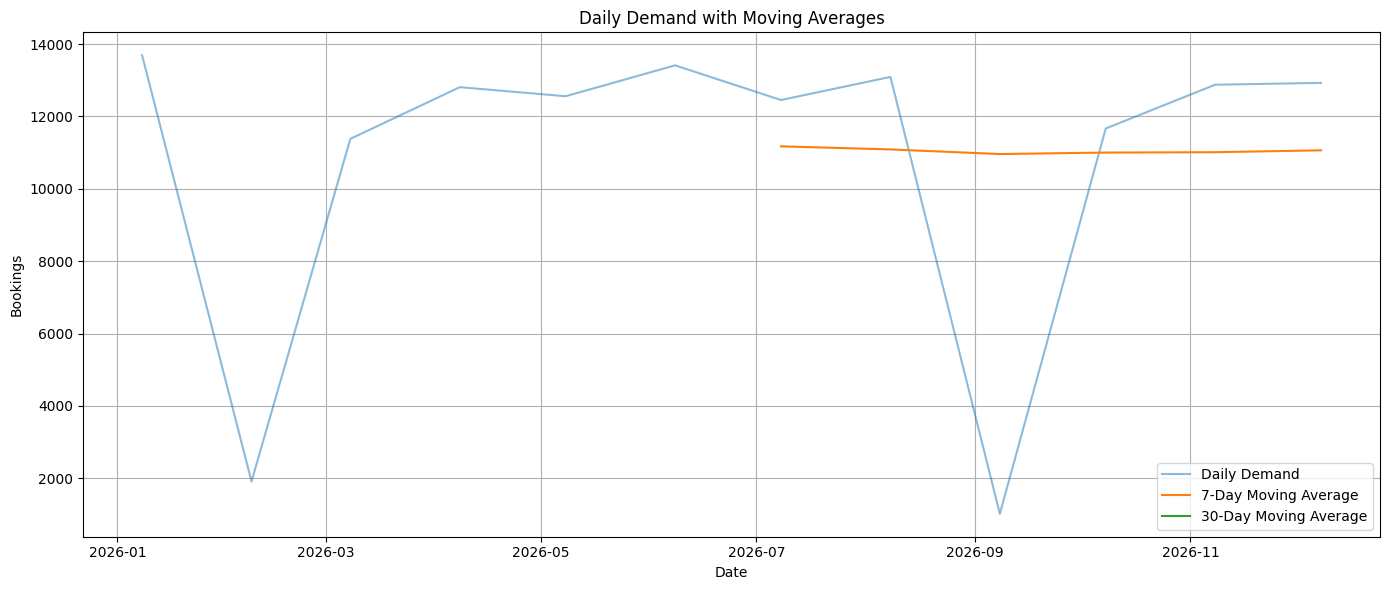

In [22]:
daily_df["7_DAY_MA"] = (
    daily_df[demand_col].rolling(window=7).mean()
)

daily_df["30_DAY_MA"] = (
    daily_df[demand_col].rolling(window=30).mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_df.index,
    daily_df[demand_col],
    label="Daily Demand",
    alpha=0.5
)

plt.plot(
    daily_df.index,
    daily_df["7_DAY_MA"],
    label="7-Day Moving Average"
)

plt.plot(
    daily_df.index,
    daily_df["30_DAY_MA"],
    label="30-Day Moving Average"
)

plt.title("Daily Demand with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Bookings")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Average booking demand by weekday:


DAY_OF_WEEK
Monday       13412.000000
Tuesday       6973.500000
Wednesday    12631.500000
Thursday     12679.000000
Friday       12559.000000
Saturday     13093.000000
Sunday        8723.666667
Name: BOOKING_COUNT, dtype: float64

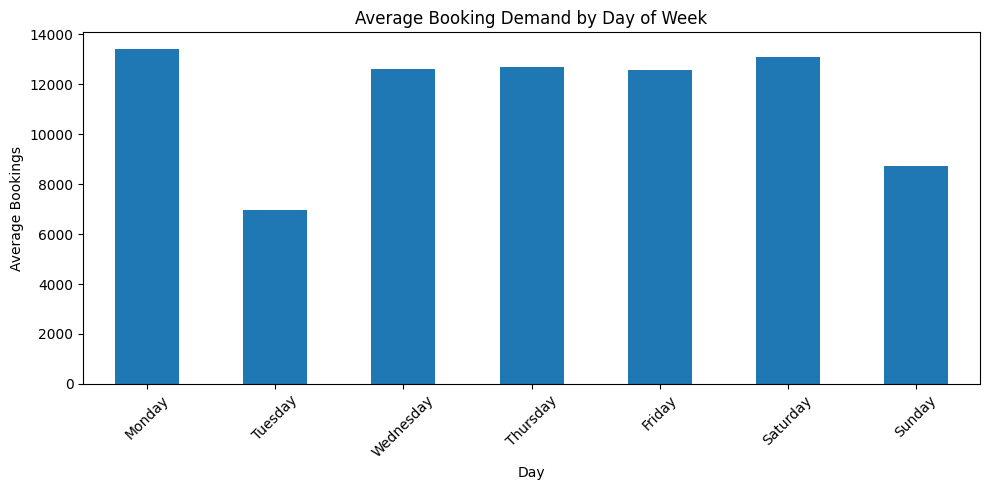

In [23]:
daily_df["DAY_OF_WEEK"] = daily_df.index.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
    daily_df.groupby("DAY_OF_WEEK")[demand_col]
    .mean()
    .reindex(weekday_order)
)

print("Average booking demand by weekday:")
display(weekday_demand)

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")

plt.title("Average Booking Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

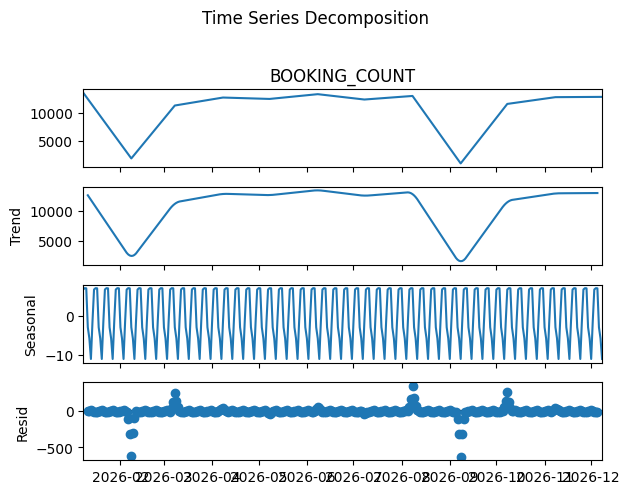

In [24]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Ensure daily frequency
regular_daily = daily_df[demand_col].asfreq("D")

# Fill missing dates for decomposition
regular_daily = regular_daily.interpolate(method="time")

if len(regular_daily) >= 14:
    decomposition = seasonal_decompose(
        regular_daily,
        model="additive",
        period=7
    )

    decomposition.plot()
    plt.suptitle("Time Series Decomposition", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Not enough data for weekly decomposition.")

In [25]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [26]:
forecast_df = daily_df[[demand_col]].copy()

# Ensure daily frequency
forecast_df = forecast_df.asfreq("D")

# Fill missing dates
forecast_df[demand_col] = (
    forecast_df[demand_col].interpolate(method="time")
)

# 80% training, 20% testing
split_index = int(len(forecast_df) * 0.8)

train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()

print("Training data:", train.shape)
print("Testing data:", test.shape)

print("\nTraining date range:")
print(train.index.min(), "to", train.index.max())

print("\nTesting date range:")
print(test.index.min(), "to", test.index.max())

Training data: (268, 1)
Testing data: (67, 1)

Training date range:
2026-01-08 00:00:00 to 2026-10-02 00:00:00

Testing date range:
2026-10-03 00:00:00 to 2026-12-08 00:00:00


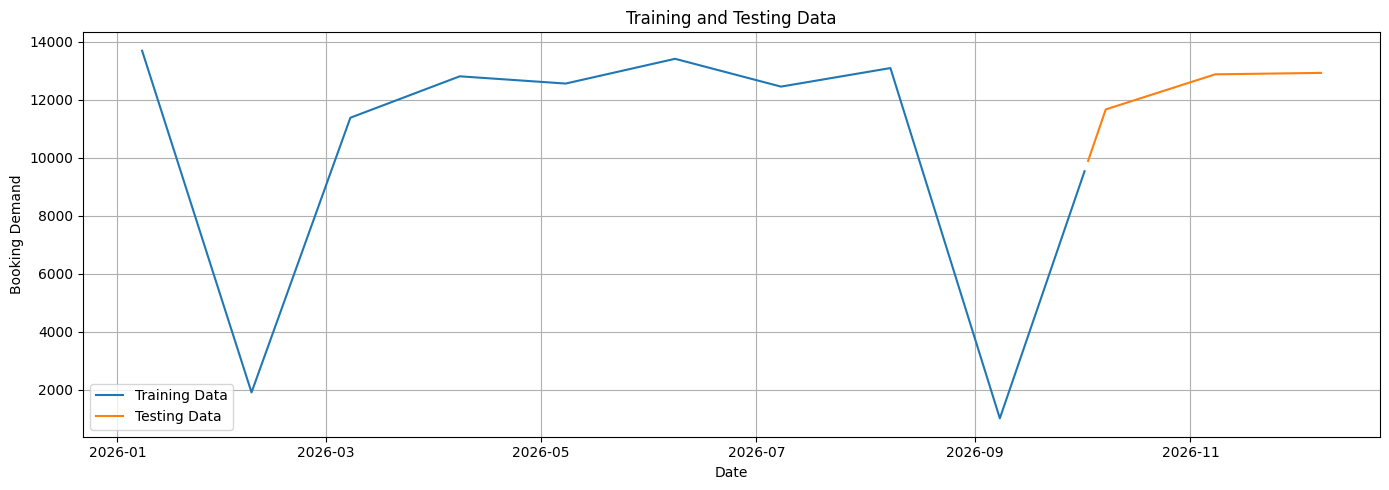

In [27]:
plt.figure(figsize=(14, 5))

plt.plot(
    train.index,
    train[demand_col],
    label="Training Data"
)

plt.plot(
    test.index,
    test[demand_col],
    label="Testing Data"
)

plt.title("Training and Testing Data")
plt.xlabel("Date")
plt.ylabel("Booking Demand")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
OUTPUT_DIR = os.path.join(PROJECT_DIR, "data", "processed")
os.makedirs(OUTPUT_DIR, exist_ok=True)

daily_df.to_csv(
    os.path.join(OUTPUT_DIR, "time_series_analysis.csv")
)

train.to_csv(
    os.path.join(OUTPUT_DIR, "train_data.csv")
)

test.to_csv(
    os.path.join(OUTPUT_DIR, "test_data.csv")
)

print("Time-series analysis files saved successfully!")

Time-series analysis files saved successfully!
